# 🖼️ PyTorch ile Bilgisayarlı Görüye Giriş (Computer Vision) & CIFAR-10 Sınıflandırma

Bu notebook'ta **PyTorch** ve **Torchvision** kütüphanelerini kullanarak bilgisayarlı görü (Computer Vision) dünyasına adım atıyoruz. Popüler **CIFAR-10** görsel veri seti üzerinde 3 farklı model mimarisini sırasıyla inşa edip karşılaştıracağız:
1. **Model 0 (Baseline Linear):** Geleneksel düzleştirme (`nn.Flatten()`) ve doğrusal katmanlar.
2. **Model 1 (Baseline Non-Linear):** Doğrusal katmanlar + `ReLU` aktivasyonu.
3. **Model 2 (TinyVGG CNN):** Evrişimli (`Conv2d`), havuzlama (`MaxPool2d`) ve sınıflandırma blokları.

---

### 🗺️ İçindekiler
1. [Gerekli Kütüphanelerin Yüklenmesi](#1-gerekli-kütüphanelerin-yüklenmesi)
2. [CIFAR-10 Veri Seti & Keşifsel Veri Analizi (EDA)](#2-cifar-10-veri-seti--keşifsel-veri-analizi-eda)
3. [Görsel Dönüşümleri (Torchvision Transforms & Normalizasyon)](#3-görsel-dönüşümleri-torchvision-transforms--normalizasyon)
4. [Mini-Batching ve DataLoader Kurulumu](#4-mini-batching-ve-dataloader-kurulumu)
5. [Model 0: Doğrusal Temel Çizgi (Baseline Linear Model)](#5-model-0-doğrusal-temel-çizgi-baseline-linear-model)
6. [Model 1: Doğrusal Olmayan Temel Çizgi (Non-Linear Model with ReLU)](#6-model-1-doğrusal-olmayan-temel-çizgi-non-linear-model-with-relu)
7. [Model 2: TinyVGG Evrişimli Sinir Ağı (CNN)](#7-model-2-tinyvgg-evrişimli-sinir-ağı-cnn)
8. [Modellerin Karşılaştırmalı Performans Analizi](#8-modellerin-karşılaştırmalı-performans-analizi)
9. [Test Tahminleri ve Görsel Doğrulama](#9-test-tahminleri-ve-görsel-doğrulama)
10. [Özet ve Çıkarılan Temel Mühendislik Dersleri](#10-özet-ve-çıkarılan-temel-mühendislik-dersleri)


## 1. Gerekli Kütüphanelerin Yüklenmesi


In [1]:

import torch
from torch import nn
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

In [2]:
# https://docs.pytorch.org/vision/main/datasets.html


In [3]:
# CIFAR10 https://www.cs.toronto.edu/~kriz/cifar.html


## 2. CIFAR-10 Veri Seti & Keşifsel Veri Analizi (EDA)

**CIFAR-10**, makine öğrenmesi ve bilgisayarlı görüde en çok kullanılan referans veri setlerinden biridir:
- **50.000 Eğitim Görseli**, **10.000 Test Görseli**.
- **10 Farklı Sınıf:** `airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`.
- **Boyut:** $32 \times 32$ piksel, **3 Renk Kanalı (RGB)**.


In [4]:
train_data = datasets.CIFAR10(
    root="data", # Veri setinin indirileceği yerel klasör
    train=True, # Eğitim veri seti
    download=True, # Veri diskte yoksa otomatik olarak indir
    transform=ToTensor(), # Görseller PIL formatında gelir; bunları PyTorch tensörüne [C, H, W] dönüştürüyoruz
    target_transform=None # İhtiyaç halinde etiket dönüşümü de uygulanabilir
)

# Test veri setini hazırlıyoruz
test_data = datasets.CIFAR10(
    root="data",
    train=False, # Test veri seti
    download=True,
    transform=ToTensor()
)

In [5]:
type(train_data)

torchvision.datasets.cifar.CIFAR10

In [6]:
train_data[0]

(tensor([[[0.2314, 0.1686, 0.1961,  ..., 0.6196, 0.5961, 0.5804],
          [0.0627, 0.0000, 0.0706,  ..., 0.4824, 0.4667, 0.4784],
          [0.0980, 0.0627, 0.1922,  ..., 0.4627, 0.4706, 0.4275],
          ...,
          [0.8157, 0.7882, 0.7765,  ..., 0.6275, 0.2196, 0.2078],
          [0.7059, 0.6784, 0.7294,  ..., 0.7216, 0.3804, 0.3255],
          [0.6941, 0.6588, 0.7020,  ..., 0.8471, 0.5922, 0.4824]],
 
         [[0.2431, 0.1804, 0.1882,  ..., 0.5176, 0.4902, 0.4863],
          [0.0784, 0.0000, 0.0314,  ..., 0.3451, 0.3255, 0.3412],
          [0.0941, 0.0275, 0.1059,  ..., 0.3294, 0.3294, 0.2863],
          ...,
          [0.6667, 0.6000, 0.6314,  ..., 0.5216, 0.1216, 0.1333],
          [0.5451, 0.4824, 0.5647,  ..., 0.5804, 0.2431, 0.2078],
          [0.5647, 0.5059, 0.5569,  ..., 0.7216, 0.4627, 0.3608]],
 
         [[0.2471, 0.1765, 0.1686,  ..., 0.4235, 0.4000, 0.4039],
          [0.0784, 0.0000, 0.0000,  ..., 0.2157, 0.1961, 0.2235],
          [0.0824, 0.0000, 0.0314,  ...,

In [7]:
type(train_data[0])

tuple

In [8]:
image,label =train_data[0]

In [9]:
image

tensor([[[0.2314, 0.1686, 0.1961,  ..., 0.6196, 0.5961, 0.5804],
         [0.0627, 0.0000, 0.0706,  ..., 0.4824, 0.4667, 0.4784],
         [0.0980, 0.0627, 0.1922,  ..., 0.4627, 0.4706, 0.4275],
         ...,
         [0.8157, 0.7882, 0.7765,  ..., 0.6275, 0.2196, 0.2078],
         [0.7059, 0.6784, 0.7294,  ..., 0.7216, 0.3804, 0.3255],
         [0.6941, 0.6588, 0.7020,  ..., 0.8471, 0.5922, 0.4824]],

        [[0.2431, 0.1804, 0.1882,  ..., 0.5176, 0.4902, 0.4863],
         [0.0784, 0.0000, 0.0314,  ..., 0.3451, 0.3255, 0.3412],
         [0.0941, 0.0275, 0.1059,  ..., 0.3294, 0.3294, 0.2863],
         ...,
         [0.6667, 0.6000, 0.6314,  ..., 0.5216, 0.1216, 0.1333],
         [0.5451, 0.4824, 0.5647,  ..., 0.5804, 0.2431, 0.2078],
         [0.5647, 0.5059, 0.5569,  ..., 0.7216, 0.4627, 0.3608]],

        [[0.2471, 0.1765, 0.1686,  ..., 0.4235, 0.4000, 0.4039],
         [0.0784, 0.0000, 0.0000,  ..., 0.2157, 0.1961, 0.2235],
         [0.0824, 0.0000, 0.0314,  ..., 0.1961, 0.1961, 0.

In [10]:
label

6

In [11]:
image.shape

torch.Size([3, 32, 32])

In [12]:
len(train_data)

50000

In [13]:
len(test_data)

10000

In [14]:
class_names = train_data.classes

In [15]:
class_names

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [16]:
len(class_names)

10

In [17]:
# 50.000 eğitim, 10.000 test görseli ve 10 farklı sınıfımız bulunuyor


### Görsel Örneklerinin İncelenmesi ve Görselleştirilmesi


In [18]:
#image, label = train_data[0]
#plt.imshow(image)
#plt.title(label)
# Bu satır şu hatayı verecektir (PyTorch [C, H, W] bekler, Matplotlib ise [H, W, C]): 
#TypeError: Görsel verisi için geçersiz şekil (3, 32, 32)

In [19]:
image, label = train_data[1]
image = image.permute(1,2,0)
image.shape

torch.Size([32, 32, 3])

Text(0.5, 1.0, 'truck')

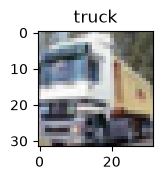

In [20]:
image, label = train_data[1]
image = image.permute(1,2,0)
plt.figure(figsize = (1.5,1.5))
plt.imshow(image)
plt.title(class_names[label])

Text(0.5, 1.0, 'deer')

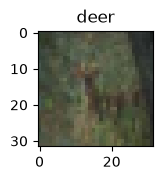

In [21]:
image, label = train_data[10]
image = image.permute(1,2,0)
plt.figure(figsize = (1.5,1.5))
plt.imshow(image)
plt.title(class_names[label])

Text(0.5, 1.0, 'airplane')

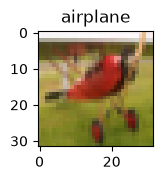

In [22]:
image, label = train_data[35]
image = image.permute(1,2,0)
plt.figure(figsize = (1.5,1.5))
plt.imshow(image)
plt.title(class_names[label])

## 3. Görsel Dönüşümleri (Torchvision Transforms & Normalizasyon)

Görsellerin derin öğrenme modeline girebilmesi için:
1. **`ToTensor()`:** PIL görselini veya NumPy dizisini `[C, H, W]` formatında `[0.0, 1.0]` aralığında PyTorch tensörüne dönüştürür.
2. **`Normalize()`:** Veri setinin RGB kanal ortalama ($\mu$) ve standart sapmalarını ($\sigma$) kullanarak pikselleri standartlaştırır (Ortalama 0, Standart Sapma 1).


In [23]:

# Görselleri inceledik; şimdi veri dönüşümlerini (Transforms) ve normalizasyonu detaylandıralım
# Çoğu durumda PIL görselini sadece tensöre çevirmek yeterli değildir; piksel değerlerini standartlaştırmak gerekir
# İlerleyen bölümlerde veri artırma (Data Augmentation) adımlarını da bu transform hattına ekleyeceğiz
from torchvision import transforms
#mean ve std ,normalizasyon yapmak şart değil eğitim yine olur ama bunu yaparsak daha hızlı ve daha verimli olur eğitim

In [24]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.491, 0.482, 0.446],
                         std=[0.247, 0.243, 0.261])
])

CIFAR10 dataset’i 50.000 eğitim görüntüsünden oluşur. Her görüntü: 3 kanal (R, G, B) ve boyut 32×32.

Bu sayılar, CIFAR10 dataset’inin tüm eğitim seti üzerinde hesaplanmış istatistiklerdir.

Yani: • mean (RGB): [0.491, 0.482, 0.446] → CIFAR10 görüntülerinin kırmızı, yeşil ve mavi kanallarının ortalaması. • std (RGB): [0.247, 0.243, 0.261] → Aynı kanalların standart sapması.

Normalize transform şu matematiği uygular:

\text{normalized} = \frac{x - \text{mean}}{\text{std}}

CNN’ler, özellikle Adam ve SGD gibi optimizasyon algoritmaları, standartlaştırılmış girişlerle çok daha iyi öğrenir.

Normalize edilmemiş görüntü: • Piksel değerleri 0–255 arasında düzensiz dağılmış • Kanal başına farklı ortalamalar • Modelin ilk katmanı için öğrenme zorlaşır

Normalize edilmiş görüntü: • Tüm görüntünün ortalaması ~ 0 • Dağılımın genişliği ~ 1 • Tüm kanallar daha benzer ölçeğe sahip

Bu: • Modelin hızlı öğrenmesini sağlar • daha stabil loss • Gradientlerin daha “dengeli” akması • Yüksek learning rate’lerin çalışabilmesi • Genel accuracy’nin ciddi şekilde artması

In [25]:
train_data = datasets.CIFAR10(
    root="data", # Veri setinin indirileceği yerel klasör
    train=True, # Eğitim veri seti
    download=True, # Veri diskte yoksa otomatik olarak indir
    transform=transform, 
    target_transform=None # İhtiyaç halinde etiket dönüşümü de uygulanabilir
)

# Test veri setini hazırlıyoruz
test_data = datasets.CIFAR10(
    root="data",
    train=False, # Test veri seti
    download=True,
    transform=transform
)

In [26]:
image, label = train_data[0]


In [27]:
image

tensor([[[-1.0511e+00, -1.3052e+00, -1.1940e+00,  ...,  5.2068e-01,
           4.2542e-01,  3.6191e-01],
         [-1.7338e+00, -1.9879e+00, -1.7021e+00,  ..., -3.5008e-02,
          -9.8516e-02, -5.0885e-02],
         [-1.5909e+00, -1.7338e+00, -1.2099e+00,  ..., -1.1439e-01,
          -8.2639e-02, -2.5728e-01],
         ...,
         [ 1.3145e+00,  1.2034e+00,  1.1558e+00,  ...,  5.5243e-01,
          -1.0988e+00, -1.1464e+00],
         [ 8.6997e-01,  7.5883e-01,  9.6523e-01,  ...,  9.3348e-01,
          -4.4780e-01, -6.7008e-01],
         [ 8.2234e-01,  6.7945e-01,  8.5409e-01,  ...,  1.4415e+00,
           4.0954e-01, -3.5008e-02]],

        [[-9.8297e-01, -1.2412e+00, -1.2089e+00,  ...,  1.4670e-01,
           3.3729e-02,  1.7591e-02],
         [-1.6608e+00, -1.9835e+00, -1.8544e+00,  ..., -5.6338e-01,
          -6.4407e-01, -5.7952e-01],
         [-1.5962e+00, -1.8706e+00, -1.5478e+00,  ..., -6.2794e-01,
          -6.2794e-01, -8.0545e-01],
         ...,
         [ 7.5995e-01,  4

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9084703..2.10758].


Text(0.5, 1.0, 'truck')

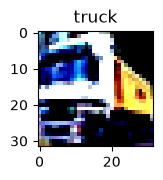

In [28]:
image, label = train_data[1]
image = image.permute(1,2,0)
plt.figure(figsize = (1.5,1.5))
plt.imshow(image)
plt.title(class_names[label])

## 4. Mini-Batching ve DataLoader Kurulumu

50.000 görseli aynı anda belleğe yüklemek yerine veriyi 32'şerli paketlere (`batch_size=32`) bölüyoruz:
- Eğitim seti için `shuffle=True` (model her epoch'ta sıralamayı ezberlemesin).
- Test seti için `shuffle=False` (değerlendirme kararlı olsun).


In [29]:
from torch.utils.data import DataLoader
# Renkler normalize edildiği için görsel farklı görünse de eğitim stabilitesi için bu çok daha faydalıdır
# DataLoader yapısına geçiyoruz: Veriyi belleği yormayacak mini-batch'lere böler
# DataLoader veriyi modele mini-batch'ler halinde vererek bellek taşmasını önler.
# Tüm veri setini tek seferde GPU/CPU belleğine sığdıramayacağımız için batching zorunludur
# Ayrıca dönüşümleri (transforms) her mini-batch için dinamik olarak uygular

In [30]:
BATCH_SIZE = 32 # Donanıma ve bellek kapasitesine göre batch_size 32, 64 veya 128 seçilebilir

train_dataloader = DataLoader(train_data,
    batch_size=BATCH_SIZE, # Her bir mini-batch'teki örnek sayısı
    shuffle=True # Eğitim verisini karıştırmak modelin sınıf sırasını ezberlemesini önler 
)

test_dataloader = DataLoader(test_data,
    batch_size=BATCH_SIZE,
    shuffle=False # Test verisini karıştırmaya gerek yoktur
)

In [31]:
len(train_dataloader), len(test_dataloader)

(1563, 313)

In [32]:
train_dataloader.dataset[0][0].shape

torch.Size([3, 32, 32])

## 5. Model 0: Doğrusal Temel Çizgi (Baseline Linear Model)

İlk olarak en ilkel yaklaşımı deniyoruz:
- **`nn.Flatten()`:** $3 \times 32 \times 32$ boyutundaki renkli görseli tek sıra halinde $3072$ elemanlı 1D vektöre açar.
- **`nn.Linear()`:** Bu $3072$ pikseli doğrudan 10 sınıfa bağlar.

> **Neden Zayıf Kalması Beklenir?**  
> Düzleştirme işlemi piksellerin birbirine olan 2 boyutlu komşuluk ilişkisini (uzamsal korelasyon) yok eder; burunun gözün altında olduğu bilgisi kaybolur.


In [33]:
# Verimiz hazır. CNN mimarisine geçmeden önce klasik doğrusal modelle başlayalım
# Klasik modelde dahi 2D/3D görsel matrisini 1D vektöre açmak için nn.Flatten() katmanı gereklidir module
# https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.flatten.Flatten.html
# Tensörün çok boyutlu uzamsal yapısını tek bir uzun özellik vektörüne dönüştürür


In [34]:
# Modeli inşa etmeden önce nn.Flatten() katmanının tensör şeklini nasıl değiştirdiğini görelim

flatten_model = nn.Flatten() # Örnek olarak Flatten katmanının tensörü nasıl açtığını test ediyoruz

first_data = train_dataloader.dataset[0][0]
flattened_data = flatten_model(first_data) 

print(f"Shape before flattening: {first_data.shape} -> [Renk_Kanalı, Yükseklik, Genişlik]")
print(f"Shape after flattening: {flattened_data.shape} -> [color_channels, height*width]")

Shape before flattening: torch.Size([3, 32, 32]) -> [color_channels, height, width]
Shape after flattening: torch.Size([3, 1024]) -> [color_channels, height*width]


In [35]:
 # Yükseklik ve genişlik piksellerini tek bir uzun öznitelik vektörüne çevirdik
# nn.Linear katmanları girdilerini 1D öznitelik vektörü olarak bekler

In [36]:
class CIFAR10Classifier(nn.Module):
    # Giriş ve çıkış şekillerini dinamik olarak alıyoruz
    # İlerleyen katmanlarda boyutları gerektiğinde kolayca ayarlayabilmek için
    # hidden_units: Gizli katmandaki nöron sayısı
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_units), # in_features: Bir örnekteki özellik sayısı (burada toplam piksel: 3 x 32 x 32 = 3072)
            nn.Linear(in_features=hidden_units, out_features=output_shape)
        )
    
    def forward(self, x):
        return self.layer_stack(x)
        

In [37]:
first_data.shape

torch.Size([3, 32, 32])

In [38]:
3 * 32 * 32

3072

In [39]:
# 3 x 32 x 32 = 3072 piksel, yani 3072 girdi özelliği


In [40]:
len(class_names)

10

In [41]:
torch.manual_seed(42)

# Modeli başlangıç parametreleriyle oluşturuyoruz
model_0 = CIFAR10Classifier(input_shape=3072, # Her bir piksel için bir girdi (3 x 32 x 32 = 3072)
    hidden_units=32, # Gizli katmandaki nöron adedi
    output_shape=len(class_names) # Her bir sınıf için bir çıktı nöronu (10 sınıf)
)

In [42]:
model_0 = torch.compile(model_0)
loss_fn = nn.CrossEntropyLoss() 
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.01)

In [43]:
def calculate_accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item() 
    acc = (correct / len(y_pred)) * 100 
    return acc

### Model 0 Eğitimi (10 Epoch)


In [44]:
torch.manual_seed(42)

epochs = 10

for epoch in range(epochs):

    ### 1. Eğitim Döngüsü (Training Loop)
    train_loss = 0
    # Eğitim mini-batch'leri üzerinde döngü kuruyoruz
    for batch, (X, y) in enumerate(train_dataloader):
        model_0.train() 
        # 1. İleri Yayılım (Forward Pass) - Model tahminlerini al
        y_pred = model_0(X)

        # 2. Kaybı Hesapla (Loss)
        loss = loss_fn(y_pred, y)
        train_loss += loss # Epoch boyunca kümülatif kaybı topla 

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # İşlenen örnek sayısını periyodik olarak ekrana yazdır
        if batch % 500 == 0:
            print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples")

    # Toplam eğitim kaybını batch sayısına bölerek ortalama kaybı bul
    train_loss /= len(train_dataloader)
    
    ### 2. Test / Değerlendirme Döngüsü (Validation Loop)
    # Kümülatif test kaybı ve doğruluk sayaçlarını sıfırla 
    test_loss, test_acc = 0, 0 
    model_0.eval()
    with torch.inference_mode():
        for X, y in test_dataloader:
            # 1. İleri Yayılım (Forward Pass) - Model tahminlerini al
            test_pred = model_0(X)
           
            # 2. Test kaybını kümülatif olarak topla
            test_loss += loss_fn(test_pred, y) # Epoch boyunca kümülatif kaybı topla

            # 3. Doğruluk (Accuracy) oranını hesapla
            test_acc += calculate_accuracy(y_true=y, y_pred=test_pred.argmax(dim=1))
        
        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)

    print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.48378 | Test loss: 2.30664, Test acc: 28.34%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.50807 | Test loss: 2.54432, Test acc: 27.77%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.52629 | Test loss: 2.35367, Test acc: 30.28%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.51174 | Test loss: 2.46566, Test acc: 26.59%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.51881 | Test loss: 2.39821, Test acc: 27.82%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

In [45]:
# Doğruluk oranı oldukça düşük (~%25), çünkü düzleştirme uzamsal komşuluk bilgisini sildi
# Tüm modelleri aynı standartta test edebilmek için ortak bir değerlendirme fonksiyonu tanımlayalım

### Model 0 Performans Değerlendirmesi


In [46]:
def evaluate_model_performance(model: torch.nn.Module, data_loader: torch.utils.data.DataLoader, 
               loss_fn: torch.nn.Module, accuracy_function):
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            y_pred = model(X)
            loss += loss_fn(y_pred, y)
            acc += accuracy_function(y_true=y, y_pred=y_pred.argmax(dim=1)) 

        # Batch başına ortalama kayıp ve doğruluğu hesapla
        loss /= len(data_loader)
        acc /= len(data_loader)
        
    return {"model_name": model.__class__.__name__,
            "model_loss": loss.item(),
            "model_acc": acc}

In [47]:
model_0_results = evaluate_model_performance(model=model_0, data_loader=test_dataloader,
    loss_fn=loss_fn, accuracy_function=calculate_accuracy)

In [48]:
model_0_results

{'model_name': 'OptimizedModule',
 'model_loss': 2.681875467300415,
 'model_acc': 25.10982428115016}

## 6. Model 1: Doğrusal Olmayan Temel Çizgi (Non-Linear Model with ReLU)

Doğrusal modelin düşük başarımı üzerine araya `ReLU` aktivasyon fonksiyonu ekliyoruz:
- Giriş katmanı ($3072 \to \text{hidden\_units}$) $\to$ `ReLU` $\to$ Çıkış katmanı ($\text{hidden\_units} \to 10$).
- Bakalım doğrusal olmama tek başına uzamsal ilişki eksikliğini telafi edebilecek mi?


In [49]:
# Doğrusal model yetersiz kaldı; araya ReLU aktivasyonu ekleyerek doğrusal olmayan modeli deneyelim


In [50]:
class CIFAR10ClassifierNonLinear(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(), 
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_shape)
        )
    
    def forward(self, x: torch.Tensor):
        return self.layer_stack(x)

In [51]:
torch.manual_seed(42)
model_1 = CIFAR10ClassifierNonLinear(input_shape=3072, 
    hidden_units=32,
    output_shape=len(class_names) 
)

In [52]:
model_1 = torch.compile(model_1)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.01)

### Model 1 Eğitimi (10 Epoch)


In [53]:
torch.manual_seed(42)

epochs = 10

for epoch in range(epochs):

    ### 1. Eğitim Döngüsü (Training Loop)
    train_loss = 0
    # Eğitim mini-batch'leri üzerinde döngü kuruyoruz
    for batch, (X, y) in enumerate(train_dataloader):
        model_1.train() 
        # 1. İleri Yayılım (Forward Pass) - Model tahminlerini al
        y_pred = model_1(X)

        # 2. Kaybı Hesapla (Loss)
        loss = loss_fn(y_pred, y)
        train_loss += loss # Epoch boyunca kümülatif kaybı topla 

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # İşlenen örnek sayısını periyodik olarak ekrana yazdır
        if batch % 500 == 0:
            print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples")

    # Toplam eğitim kaybını batch sayısına bölerek ortalama kaybı bul
    train_loss /= len(train_dataloader)
    
    ### 2. Test / Değerlendirme Döngüsü (Validation Loop)
    # Kümülatif test kaybı ve doğruluk sayaçlarını sıfırla 
    test_loss, test_acc = 0, 0 
    model_1.eval()
    with torch.inference_mode():
        for X, y in test_dataloader:
            # 1. İleri Yayılım (Forward Pass) - Model tahminlerini al
            test_pred = model_1(X)
           
            # 2. Test kaybını kümülatif olarak topla
            test_loss += loss_fn(test_pred, y) # Epoch boyunca kümülatif kaybı topla

            # 3. Doğruluk (Accuracy) oranını hesapla
            test_acc += calculate_accuracy(y_true=y, y_pred=test_pred.argmax(dim=1))
        
        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)

    print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.34762 | Test loss: 2.30951, Test acc: 28.57%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.29904 | Test loss: 2.53263, Test acc: 27.11%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.22626 | Test loss: 2.20705, Test acc: 29.75%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.19953 | Test loss: 2.20463, Test acc: 28.38%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 2.17065 | Test loss: 2.17916, Test acc: 30.36%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

### Model 1 Performans Değerlendirmesi


In [54]:
model_1_results = evaluate_model_performance(model=model_1, data_loader=test_dataloader,
    loss_fn=loss_fn, accuracy_function=calculate_accuracy)

In [55]:
model_1_results

{'model_name': 'OptimizedModule',
 'model_loss': 2.2974324226379395,
 'model_acc': 24.900159744408946}

In [56]:
model_0_results

{'model_name': 'OptimizedModule',
 'model_loss': 2.681875467300415,
 'model_acc': 25.10982428115016}

In [57]:
# Görüldüğü gibi sadece aktivasyon eklemek piksel komşuluğu olmadan başarıyı pek artırmadı (~%25)


## 7. Model 2: TinyVGG Evrişimli Sinir Ağı (CNN)

Görseli düzleştirmek yerine piksellerin 2 boyutlu uzamsal ilişkisini koruyan **Evrişimli Sinir Ağı (CNN)** mimarisine geçiyoruz.  
Kullandığımız mimari [CNN Explainer](https://poloclub.github.io/cnn-explainer/) sitesinde tanıtılan **TinyVGG** mimarisidir:

* **Conv Blok 1:**
  * `nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)` $\to$ `ReLU()`
  * `nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1)` $\to$ `ReLU()`
  * `nn.MaxPool2d(kernel_size=2)` $\implies$ Boyut: $32 \times 32 \to 16 \times 16$
* **Conv Blok 2:**
  * `nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1)` $\to$ `ReLU()`
  * `nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1)` $\to$ `ReLU()`
  * `nn.MaxPool2d(kernel_size=2)` $\implies$ Boyut: $16 \times 16 \to 8 \times 8$
* **Sınıflandırıcı (Classifier):**
  * `nn.Flatten()` $\implies 32 \times 8 \times 8 = 2048$ özellik
  * `nn.Linear(in_features=hidden_units * 8 * 8, out_features=10)`


In [58]:
# Doğruluğu nasıl artırabiliriz? Daha iyi veri dönüşümleri ve görsele uygun bir model (CNN) gerekiyor
# CNN mimarisi pikseller arasındaki 2D uzamsal ilişkileri koruyarak başarıyı belirgin şekilde artıracaktır


In [59]:
# https://poloclub.github.io/cnn-explainer/


In [60]:
# Girdi Katmanı -> [Evrişim (Conv) -> Aktivasyon (ReLU) -> Havuzlama (MaxPool)] -> Çıktı Katmanı


In [61]:
# CNN Explainer sitesindeki TinyVGG mimarisini inşa ediyoruz 


In [62]:
class CIFAR10ClassifierCNN(nn.Module):

    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, 
                      out_channels=hidden_units, 
                      kernel_size=3, # Resim üzerinde kayan filtrenin (kernel) boyutu (3x3)
                      stride=1, # Varsayılan: 1 piksel kaydırma
                      padding=1),# padding=1: 3x3 kernel ile orijinal uzamsal boyutu (32x32) korur 
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, 
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2) # MaxPool'da varsayılan stride değeri kernel_size ile aynıdır (2)
        )
        self.block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Bu in_features boyutu nereden geldi? 
            # Her havuzlama katmanı uzamsal boyutu yarıya indirir: 32 -> 16 -> 8. Yani hidden_units * 8 * 8!
            nn.Linear(in_features=hidden_units*8*8, 
                      out_features=output_shape)
        )
    
    def forward(self, x: torch.Tensor):
        return self.classifier(self.block_2(self.block_1(x))) 

In [63]:

torch.manual_seed(42)
model_2 = CIFAR10ClassifierCNN(input_shape=3, #3 renk kanalı (RGB) 
    hidden_units=32, 
    output_shape=len(class_names))

In [64]:
model_2

CIFAR10ClassifierCNN(
  (block_1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_2): Sequential(
    (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=10, bias=True)
  )
)

In [65]:

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_2.parameters(), lr=0.01)

### Model 2 (CNN) Eğitimi (10 Epoch)


In [66]:
torch.manual_seed(42)

epochs = 10

for epoch in range(epochs):

    ### 1. Eğitim Döngüsü (Training Loop)
    train_loss = 0
    # Eğitim mini-batch'leri üzerinde döngü kuruyoruz
    for batch, (X, y) in enumerate(train_dataloader):
        model_2.train() 
        # 1. İleri Yayılım (Forward Pass) - Model tahminlerini al
        y_pred = model_2(X)

        # 2. Kaybı Hesapla (Loss)
        loss = loss_fn(y_pred, y)
        train_loss += loss # Epoch boyunca kümülatif kaybı topla 

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # İşlenen örnek sayısını periyodik olarak ekrana yazdır
        if batch % 500 == 0:
            print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples")

    # Toplam eğitim kaybını batch sayısına bölerek ortalama kaybı bul
    train_loss /= len(train_dataloader)
    
    ### 2. Test / Değerlendirme Döngüsü (Validation Loop)
    # Kümülatif test kaybı ve doğruluk sayaçlarını sıfırla 
    test_loss, test_acc = 0, 0 
    model_2.eval()
    with torch.inference_mode():
        for X, y in test_dataloader:
            # 1. İleri Yayılım (Forward Pass) - Model tahminlerini al
            test_pred = model_2(X)
           
            # 2. Test kaybını kümülatif olarak topla
            test_loss += loss_fn(test_pred, y) # Epoch boyunca kümülatif kaybı topla

            # 3. Doğruluk (Accuracy) oranını hesapla
            test_acc += calculate_accuracy(y_true=y, y_pred=test_pred.argmax(dim=1))
        
        test_loss /= len(test_dataloader)
        test_acc /= len(test_dataloader)

    print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 1.82070 | Test loss: 1.73704, Test acc: 38.73%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 1.66159 | Test loss: 1.62140, Test acc: 40.34%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 1.61481 | Test loss: 1.63237, Test acc: 40.20%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 1.59532 | Test loss: 1.57522, Test acc: 43.10%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

Train loss: 1.55353 | Test loss: 1.52065, Test acc: 45.24%

Looked at 0/50000 samples
Looked at 16000/50000 samples
Looked at 32000/50000 samples
Looked at 48000/50000 samples

### Model 2 Performans Değerlendirmesi


In [67]:
model_2_results = evaluate_model_performance(model=model_2, data_loader=test_dataloader,
    loss_fn=loss_fn, accuracy_function=calculate_accuracy)

## 8. Modellerin Karşılaştırmalı Performans Analizi

3 modelin CIFAR-10 test veri seti üzerindeki doğruluk (Accuracy) ve hata (Loss) sonuçlarını yan yana koyalım:


In [68]:
model_0_results

{'model_name': 'OptimizedModule',
 'model_loss': 2.681875467300415,
 'model_acc': 25.10982428115016}

In [69]:
model_1_results

{'model_name': 'OptimizedModule',
 'model_loss': 2.2974324226379395,
 'model_acc': 24.900159744408946}

In [70]:
model_2_results

{'model_name': 'CIFAR10ClassifierCNN',
 'model_loss': 1.5381643772125244,
 'model_acc': 43.480431309904155}

In [71]:
# Görüldüğü üzere CNN ile doğruluk oranı neredeyse iki katına çıktı (%43.5)!


### 📊 Karşılaştırma Özeti Tablosu:

| Model Mimarisi | Test Loss | Test Accuracy (%) | Yorum |
| :--- | :---: | :---: | :--- |
| **Model 0 (Linear Baseline)** | ~2.68 | ~%25.1 | Düzleştirme uzamsal bilgiyi sildiği için başarısız. |
| **Model 1 (Non-Linear + ReLU)** | ~2.30 | ~%24.9 | Sadece aktivasyon eklemek piksel komşuluğu olmadan yetersiz. |
| **Model 2 (TinyVGG CNN)** | **~1.54** | **~%43.5** | **Doğruluk neredeyse 2 katına çıktı!** Evrişim filtreleri kenarları ve dokuları öğrendi. |


## 9. Test Tahminleri ve Görsel Doğrulama

Eğittiğimiz modellerin test setindeki rastgele görseller üzerinde ürettiği tahminleri görselleştiriyoruz.  
Doğru tahminler **Yeşil**, hatalı tahminler **Kırmızı** renkle başlıkta gösterilir.


In [72]:
# Şimdi eğittiğimiz Model 2 (CNN) ile rastgele test görselleri üzerinde tahmin yapıp görselleştirelim


In [73]:
def make_predictions(model: torch.nn.Module, data: list):
    """
    data: [img_tensor, img_tensor, ...]  # her biri [C, H, W]
    return: [N, num_classes] olasılık tensörü
    """
    pred_probs = []
    model.eval()

    with torch.inference_mode():
        for sample in data:
            # [C, H, W] -> [1, C, H, W]
            sample = sample.unsqueeze(0)

            # Logits al
            pred_logit = model(sample)    # shape: [1, num_classes]

            # Softmax ile olasılığa çevir
            prob = torch.softmax(pred_logit, dim=1)  # [1, num_classes]

            # Batch boyutunu sıkıştır
            pred_probs.append(prob.squeeze(0))       # [num_classes]

    # Hepsini birleştir → [N, num_classes]
    return torch.stack(pred_probs)

In [74]:
import random
def show_random_predictions(model, dataset, class_names, n=9):
    model.eval()
    
    plt.figure(figsize=(4, 4))

    # random 9 index seç
    indices = random.sample(range(len(dataset)), n)

    with torch.inference_mode():
        for i, idx in enumerate(indices):
            img, true_label = dataset[idx]

            # modele uygun hale getir
            img_input = img.unsqueeze(0)  
            logits = model(img_input)
            pred_label = logits.argmax(dim=1).item()

            # görseli çizmek için permute
            img_show = img.permute(1, 2, 0)

            # doğru mu yanlış mı?
            correct = (pred_label == true_label)
            color = "green" if correct else "red"

            # subplot
            plt.subplot(3, 3, i + 1)
            plt.imshow(img_show)
            plt.axis("off")

            plt.title(
                f"Pred: {class_names[pred_label]}\nTrue: {class_names[true_label]}",
                color=color,
                fontsize=10
            )

    plt.tight_layout()
    plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7973328..1.9019608].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9878542..1.8250626].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9878542..1.6959574].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9561007..1.1309444].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8449631..1.7469761].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9719775..2.044852].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8867102

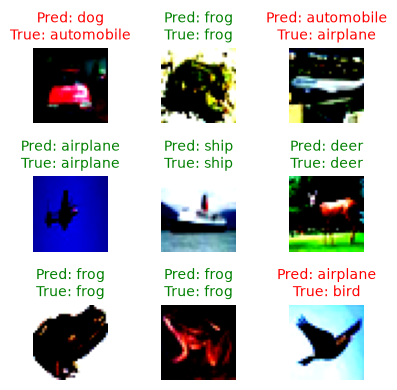

In [75]:
show_random_predictions(model_2, test_data, class_names)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6123618..1.8896152].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9878542..2.1316872].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8449631..2.1226053].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6226879..2.0607288].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9878542..1.0604907].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.4004128..2.083273].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9878542

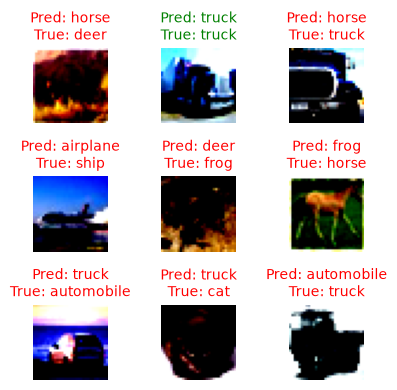

In [76]:
show_random_predictions(model_0, test_data, class_names)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6769143..1.1716282].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9835391..1.8671775].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5962237..2.1316872].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6769143..2.0775297].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.86084..1.8067001].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9719775..1.8702073].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9878542.

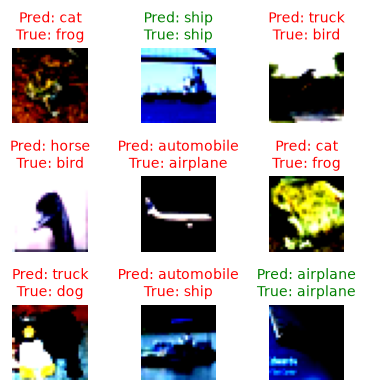

In [77]:
show_random_predictions(model_1, test_data, class_names)


## 10. Özet ve Çıkarılan Temel Mühendislik Dersleri

1. **Görseller Tablo Değildir:** Görseli `Flatten()` ile dümdüz edip klasik yapay sinir ağına (`nn.Linear`) vermek, pikseller arasındaki komşuluk ve geometriyi çöpe atar.
2. **CNN'in Gücü (Spatial Invariance & Feature Hierarchy):**
   * İlk konvolüsyon katmanları düşük seviyeli özellikleri (kenarlar, çizgiler, köşeler) öğrenir.
   * İlerleyen katmanlar bu kenarları birleştirip karmaşık şekilleri (tekerlek, kanat, göz) tanır.
3. **Parametre Verimliliği:** CNN tüm görseli aynı devasa matrisle bağlamak yerine küçük $3 \times 3$ filtreleri paylaşarak (Weight Sharing) çok daha az parametreyle çok daha yüksek başarıya ulaşır.
